# LAB — Local AI with Ollama

**Module:** Artificial Intelligence / Generative AI
**Level:** PhD Students
**Environment:** Google Colab (T4 GPU) or your own computer
**Technologies:** Ollama, Python, REST API, `requests`, Flask, local LLMs (Qwen, Gemma)

**Prerequisites:** Python 3.10+, basic Python, basic understanding of APIs, 8 to 16 GB of RAM (an NVIDIA GPU helps but is not required).

Ollama runs a small HTTP server on `localhost:11434`. Once a model is downloaded, the same model can be used from the terminal, from Python, or from any other program that can send an HTTP request.

### How to use this notebook
- Run the cells from top to bottom. Cells starting with `!` are shell commands.
- On Colab, choose **Runtime > Change runtime type > T4 GPU** before starting. The install cells below only run on Colab; on your own computer install Ollama from the website instead.
- The models are set in `MODEL` / `MODEL2` (Exercise 3). Change them if you want to try other ones.
- The **Your answer** cells and Part 18 contain my answers, based on the outputs of this run (Colab, T4 GPU).


## Part 1 — Understanding Local AI

**Cloud AI**
```
Python App → Internet → Cloud API → LLM
```
**Local AI**
```
Python App → localhost:11434 → Ollama → Local LLM → GPU / CPU
```
Advantages to investigate: **privacy**, **offline operation**, **no cost per token**.
The price to pay: local models can be **less capable or slower** than the big cloud models, depending on the hardware and the model size.

> Note for Colab: here "local" means local to the Colab machine. The model runs on the T4 GPU of the virtual machine, and the notebook talks to it through `localhost`, exactly like on a laptop.


## Part 2 — Installing Ollama
### Exercise 1 — Verify the environment

In [1]:
# Google Colab setup: get the lab files from the repository.
import os
if not os.path.exists("image.jpg"):
    !git clone -q https://github.com/yassirtl/Local-AI-Ollama-Lab.git
    %cd Local-AI-Ollama-Lab


/content/Local-AI-Ollama-Lab


In [2]:
import sys, platform
print("Python :", sys.version)
print("System :", platform.system(), platform.release())
assert sys.version_info >= (3, 10), "Python 3.10+ required"

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running on Colab:", IN_COLAB)


Python : 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
System : Linux 6.6.122+
Running on Colab: True


In [3]:
!pip --version
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

pip 24.1.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


### Exercise 2 — Install Ollama
On your own computer, download the installer from <https://ollama.com/download> (Linux: `curl -fsSL https://ollama.com/install.sh | sh`).

On Colab we use the Linux script. It needs `zstd` to unpack the archive and `pciutils` to detect the GPU, so we install them first.


In [4]:
if IN_COLAB:
    !apt-get -qq install -y zstd pciutils > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh

>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [5]:
!ollama --version

Ollama must be running before we can use it. The desktop app starts it automatically; otherwise you run `ollama serve` in a separate terminal.

Colab has no second terminal, so we start `ollama serve` as a background process from Python and wait until it answers.


In [6]:
import subprocess, time, requests

def ollama_running():
    try:
        return requests.get("http://localhost:11434", timeout=3).ok
    except requests.exceptions.RequestException:   # refused or no answer yet
        return False

if not ollama_running():
    ollama_log = open("ollama.log", "w")
    ollama_proc = subprocess.Popen(["ollama", "serve"], stdout=ollama_log, stderr=subprocess.STDOUT)
    for _ in range(60):
        if ollama_running():
            break
        time.sleep(2)
print("Ollama running:", ollama_running())

Ollama running: True


In [7]:
import requests

OLLAMA = "http://localhost:11434"

try:
    r = requests.get(OLLAMA, timeout=3)
    print("Ollama server reachable:", r.text)
except requests.exceptions.ConnectionError:
    print("Ollama is not running. Start it with `ollama serve` in a terminal.")


Ollama server reachable: Ollama is running


## Part 3 — Your First Local LLM
### Exercise 3 — Download a model
We use `qwen3.5:9b` (about 6.6 GB) and `gemma3:4b` (about 3.3 GB). Both fit together in the 15 GB of the T4. On a laptop with less memory, take a smaller version (for example `qwen3.5:4b` or `gemma3:1b`).


In [8]:
# Models used in the lab, change them if needed
MODEL  = "qwen3.5:9b"   # Model 1
MODEL2 = "gemma3:4b"    # Model 2 (comparison parts and vision)

In [9]:
!ollama pull {MODEL} 2>&1 | tr '\r' '\n' | tail -n 2

writing manifest 
success 


In [10]:
!ollama list

NAME          ID              SIZE      MODIFIED               
qwen3.5:9b    56671c2ab938    6.6 GB    Less than a second ago    


### Exercise 4 — Run the model
In a terminal you would type `ollama run qwen3.5:9b` and chat with it. Here we do the same thing through the API, with a small helper function.


In [11]:
import time, json

def generate(prompt, model=None, system=None, fmt=None, images=None, options=None, think=None):
    """Call Ollama /api/generate (non-streaming) and return the full JSON dict
    plus the measured wall-clock time under the key 'wall_s'."""
    payload = {"model": model or MODEL, "prompt": prompt, "stream": False}
    if system:  payload["system"] = system
    if fmt:     payload["format"] = fmt          # "json" or a JSON schema
    if images:  payload["images"] = images       # list of base64 strings
    if options: payload["options"] = options
    if think is not None: payload["think"] = think  # False disables 'thinking' on reasoning models
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA}/api/generate", json=payload, timeout=600)
    r.raise_for_status()
    out = r.json()
    out["wall_s"] = time.perf_counter() - t0
    return out

def ask(prompt, **kw):
    """Shortcut: return only the text, and print timing."""
    out = generate(prompt, **kw)
    print(f"[{out['wall_s']:.1f}s]")
    return out["response"]

In [12]:
for p in [
    "Explain what artificial intelligence is in five sentences.",
    "Explain artificial intelligence to a 10-year-old child.",
    "Explain artificial intelligence to a computer science professor.",
]:
    print("="*80, "\nPROMPT:", p, "\n")
    print(ask(p))

PROMPT: Explain what artificial intelligence is in five sentences. 

[150.1s]
Artificial intelligence is a branch of computer science focused on creating machines that can perform tasks requiring human-like cognitive skills. These systems utilize complex algorithms and machine learning models to process data, recognize patterns, and make decisions autonomously. Instead of being explicitly programmed for every action, AI evolves by training on large datasets to improve its accuracy and adaptability over time. Current applications include virtual assistants, automated customer service tools, self-driving cars, and sophisticated medical diagnostic software. As technology advances, the aim is to integrate these capabilities more deeply into society to solve complex problems and enhance human productivity.
PROMPT: Explain artificial intelligence to a 10-year-old child. 

[40.0s]
Imagine you have a really smart robot friend who never gets tired, never falls asleep, and has read every book in

Check that the model is really running on the GPU (the `PROCESSOR` column should say `100% GPU`):

In [13]:
!ollama ps

NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen3.5:9b    56671c2ab938    5.6 GB    100% GPU     4096       llamacpp    4 minutes from now    


### Questions
1. Did the model produce different answers? Why?
2. Is the model communicating with a cloud API?
3. Where is inference being performed?
4. What happens if the Internet connection is disabled?

> On a laptop: turn off Wi-Fi and run the cell again. On Colab you cannot cut the Internet of the VM, but you can check where the requests go (`localhost`) and what `ollama ps` shows.

**Your answer:**

**1. Did the model produce different answers? Why?**
Yes, very different. The three prompts ask for the same topic but for a different audience, and the model adapts the vocabulary, the length and the structure:
- "five sentences": exactly five plain sentences (definition, learning from data, applications, future).
- "10-year-old child": a "smart robot friend" analogy, examples from daily life (Netflix, YouTube, Siri/Alexa), and a reassuring tone ("AI is not perfect (and that's okay!)").
- "computer science professor": formal vocabulary (symbolic AI vs connectionism, distributional shift, inductive bias, causal reasoning) and a structured answer with sections.

There is also a second reason: even with the same prompt, the text would change at each run, because the model *samples* the next token. `ollama show` (Part 5) gives the sampling parameters of qwen3.5: `temperature 1`, `top_k 20`, `top_p 0.95`, so the output is not deterministic.

**2. Is the model communicating with a cloud API?**
No. `generate()` sends a POST request to `http://localhost:11434/api/generate`, which is the Ollama server running on the same machine. There is no API key and no external host in the code. The Internet was used only once, to download the model weights with `ollama pull`.

**3. Where is inference being performed?**
On the T4 GPU of the Colab machine. `ollama ps` shows `qwen3.5:9b`, `5.6 GB`, `100% GPU`, with a context of 4096 tokens: all the weights are in GPU memory and the llama.cpp runner of Ollama computes the tokens there.

About the time: the first answer took 150 s, the next ones 40 s and 75 s. The first call includes loading the model into the GPU, and qwen3.5 is a "thinking" model (thinking is on by default), so it writes a hidden reasoning before the answer. This reasoning is not in `response` but it costs time.

**4. What happens if the Internet connection is disabled?**
On a laptop, the cells above keep working: the model is on the disk and the request never leaves the computer. Only `ollama pull` (and installing Ollama) needs the Internet.
On Colab I could not test it, because the browser talks to the Colab VM through the Internet, so cutting the connection also cuts the notebook. But the code shows the same thing: the only address used is `localhost`, so the model does not depend on any online service once it is downloaded.


## Part 4 — Experiment with Prompts
### Exercise 5 — Prompt engineering

In [14]:
prompt_a = """You are a university professor.

Explain the concept of a Directed Acyclic Graph (DAG).

Your answer must contain:
1. Definition
2. Example
3. Adjacency matrix
4. Real-world application
5. One Python example"""

print(ask(prompt_a))

[120.1s]
Hello class! Please take a seat. Today we are going to delve into a fundamental structure in computer science and mathematics: the **Directed Acyclic Graph**, or as we abbreviate it here today, the **DAG**.

You will encounter this structure frequently when dealing with dependencies, scheduling, and flow control. Let us break this down systematically.

### 1. Definition
Formally, a graph $G$ is defined by a set of vertices (nodes) $V$ and a set of edges (connections) $E$. A **Directed Acyclic Graph** is a graph with two specific properties:

*   **Directed**: The edges have directionality. An edge from node $A$ to node $B$ ($A \to B$) implies a one-way relationship, meaning you can travel from $A$ to $B$, but not necessarily the reverse.
*   **Acyclic**: There are no cycles in the graph. This means there is no path that starts and ends at the same vertex. If you follow the arrows, you can never return to your starting point.

Because of this acyclic property, DAGs allow for a 

In [15]:
prompt_b = """You are a university professor.

Explain DAGs to a first-year computer science student.

Use simple language and one concrete example."""

print(ask(prompt_b))

[107.9s]
Hello there! Welcome to our introduction to data structures. Pull up a chair.

Today, we are talking about something called a **DAG**. Don't panic if the acronym sounds like a mouthful yet. We're going to break it down piece by piece using a very simple example that you'll use every single day in your degree.

### The Name Breakdown
Think of "DAG" as just three descriptions of a map:
1.  **Graph:** Just like a subway map or a social network (Facebook). It has dots and lines connecting them. In our case, the dots are things that need to happen, and the lines show how they connect.
2.  **Directed:** This means the connection is one-way. The arrow points from "Thing A" to "Thing B." It tells us there is a specific order. You can't go backward against the arrow.
3.  **Acyclic:** "Cycle" means a loop, or going in circles. If you follow the arrows, you must eventually stop. You cannot start at a point, follow lines, and come back to your exact starting point without repeating a step

### Questions
Compare the two answers. Explain the role of: **role · context · constraints · output format · specificity**.

**Your answer:**

Both prompts use the same role ("You are a university professor"), but the answers are very different.

- **Prompt A** (120 s) gave a formal lesson that follows the 5 requested points exactly, as 5 headings: definition with sets V and E, an example (course prerequisites), an adjacency matrix in LaTeX, build systems and Git as applications, and a Python adjacency list.
- **Prompt B** (108 s) gave an informal explanation ("Pull up a chair", "No time machines!") with one example (Math 101 → CS 101 → Algorithms 201), no matrix and no code.

Role of each element:
- **Role:** sets the voice. In both answers the model starts like a teacher in front of a class ("Hello class! Please take a seat.").
- **Context:** who the answer is for. "First-year student" in B changed the level: simple words, everyday analogies, no formal notation.
- **Constraints:** what must be in the answer. The list in A forced the matrix and the Python example; B had none of them because they were not asked.
- **Output format:** the numbered list in A became the structure of the answer (sections 1 to 5). In B the model chose its own structure and added parts I did not ask for ("Why should you care?").
- **Specificity:** the more precise the prompt, the more predictable and complete the answer. B was more open, so the model decided more by itself.

A precise prompt does not make the content correct, though. In A the model writes that in Git "every commit has one parent", which is wrong: a merge commit has two parents (and that is exactly why Git history is a DAG and not a tree).


## Part 5 — Model Management
### Exercise 6 — List, show, and monitor models

In [16]:
!ollama list

NAME          ID              SIZE      MODIFIED      
qwen3.5:9b    56671c2ab938    6.6 GB    8 minutes ago    


In [17]:
!ollama show {MODEL}

  Model
    architecture        qwen35             
    parameters          9.0B               
    context length      262144             
    embedding length    4096               
    quantization        Q4_K_M             
    requires            0.30.0             
    renderer            qwen3.5            
    parser              qwen3.5            
    template source     renderer_parser    

  Capabilities
    completion     
    vision         
    tools          
    thinking       
        levels     false, true    
        default    true           

  Projector
    architecture        clip       
    parameters          456.01M    
    embedding length    1152       
    dimensions          4096       

  Parameters
    presence_penalty    1.5     
    temperature         1       
    top_k               20      
    top_p               0.95    

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [18]:
!ollama ps

NAME          ID              SIZE      PROCESSOR    CONTEXT    RUNNER      UNTIL              
qwen3.5:9b    56671c2ab938    5.6 GB    100% GPU     4096       llamacpp    4 minutes from now    


The same information is available from the REST API (`/api/tags`, `/api/show`, `/api/ps`):

In [19]:
import pandas as pd

def downloaded_models():
    tags = requests.get(f"{OLLAMA}/api/tags").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "family": m["details"].get("family"),
        "params": m["details"].get("parameter_size"),
        "quantization": m["details"].get("quantization_level"),
    } for m in tags])

def loaded_models():
    ps = requests.get(f"{OLLAMA}/api/ps").json()["models"]
    return pd.DataFrame([{
        "name": m["name"],
        "size_GB": round(m["size"]/1e9, 2),
        "in_VRAM_GB": round(m.get("size_vram", 0)/1e9, 2),
        "expires_at": m.get("expires_at"),
    } for m in ps])

print("Downloaded:"); display(downloaded_models())
print("Currently loaded in memory:"); display(loaded_models())

Downloaded:


,name,size_GB,family,params,quantization
0,qwen3.5:9b,6.55,qwen35,9.0B,Q4_K_M


Currently loaded in memory:


,name,size_GB,in_VRAM_GB,expires_at
0,qwen3.5:9b,5.61,5.61,2026-10-22T15:07:08.897918453Z


### Questions
- What information do you get from `ollama list` vs `ollama ps`?
- What is the difference between a model that is **downloaded** and one that is **loaded**?

**Your answer:**

- `ollama list` shows the models **stored on the disk**: name, ID, size (6.6 GB for qwen3.5:9b) and date.
- `ollama show` describes **one model**: architecture `qwen35`, 9.0B parameters, quantization `Q4_K_M`, maximum context 262144 tokens, its capabilities (completion, vision, tools, thinking), the vision projector (CLIP, 456M parameters), the default sampling parameters and the license.
- `ollama ps` shows the models **currently in memory**: size in memory (5.6 GB), where they run (`100% GPU`), the context allocated (4096) and when they will be unloaded ("4 minutes from now").

**Downloaded vs loaded:** a downloaded model is just a file on the disk. It uses disk space but nothing else. A loaded model is copied into the GPU (or RAM) and ready to answer at once. Ollama unloads a model after about 5 minutes without requests (`keep_alive`), and the next request then has to load it again. In the benchmark (Part 16) I forced this "cold start": loading took 35.8 s for qwen3.5:9b and 13.0 s for gemma3:4b, before the first token.

The size in memory (5.61 GB) is not the same as the file size (6.55 GB). What is in memory depends on what Ollama actually allocates (for example the context of 4096 tokens), so it is not simply the size of the file.


## Part 6 — Compare Two Local Models
Install a second model suited to your computer.

In [20]:
!ollama pull {MODEL2} 2>&1 | tr '\r' '\n' | tail -n 2
!ollama list

writing manifest 
success 
NAME          ID              SIZE      MODIFIED               
gemma3:4b     68ceab7e468a    3.4 GB    Less than a second ago    
qwen3.5:9b    56671c2ab938    6.6 GB    8 minutes ago             


### Exercise 7 — Same prompt, different models

In [21]:
prime_prompt = """Write a Python function that determines whether a number is prime.

Requirements:
- Python
- Type hints
- Docstring
- Explain the algorithm
- Give its time complexity"""

results = {}
for m in (MODEL, MODEL2):
    print("="*80, f"\nMODEL: {m}\n")
    out = generate(prime_prompt, model=m)
    results[m] = out
    print(out["response"])
    print(f"\nTime: {out['wall_s']:.1f}s")

MODEL: qwen3.5:9b

Here's a Python function that determines whether a number is prime. It includes type hints, a detailed docstring, an explanation of the algorithm, and its time complexity analysis.

```python
def is_prime(n: int) -> bool:
    """
    Determine whether a number is prime.

    Args:
        n (int): The integer to check for primality.

    Returns:
        bool: True if 'n' is a prime number, False otherwise.

    Examples:
        >>> is_prime(2)
        True
        >>> is_prime(17)
        True
        >>> is_prime(18)
        False
        >>> is_prime(1)
        False
        >>> is_prime(97)
        True
    """

    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False

    # Check for odd divisors up to the square root of n
    limit = int(n ** 0.5) + 1
    for i in range(3, limit, 2):
        if n % i == 0:
            return False

    return True
```

### Algorithm Explanation

1. **Numbers Less Than 2**: B

Now fill in your evaluation (scores out of 5) and see the table:

In [22]:
scores = {
    MODEL:  {"Response quality /5": 5, "Code correctness /5": 5},
    MODEL2: {"Response quality /5": 4, "Code correctness /5": 5},
}

table = pd.DataFrame([
    {"Model": m, "Response time (s)": round(results[m]["wall_s"], 1), **scores[m]}
    for m in (MODEL, MODEL2)
])
table

,Model,Response time (s),Response quality /5,Code correctness /5
0,qwen3.5:9b,40.3,5,5
1,gemma3:4b,43.3,4,5


**Tip:** test the generated code. Below, the functions written by the two models are copied from the output above and compared with a reference.

In [23]:
def is_prime_reference(n: int) -> bool:
    if n < 2: return False
    if n < 4: return True
    if n % 2 == 0: return False
    i = 3
    while i * i <= n:
        if n % i == 0: return False
        i += 2
    return True

# function written by qwen3.5:9b (docstring shortened)
def is_prime_qwen(n: int) -> bool:
    """Determine whether a number is prime."""
    if n < 2:
        return False
    if n == 2:
        return True
    if n % 2 == 0:
        return False

    # Check for odd divisors up to the square root of n
    limit = int(n ** 0.5) + 1
    for i in range(3, limit, 2):
        if n % i == 0:
            return False

    return True

# function written by gemma3:4b (docstring shortened, example prints removed)
def is_prime_gemma(number: int) -> bool:
    """Determines whether a given number is prime."""
    if number <= 1:
        return False  # Numbers less than or equal to 1 are not prime

    for i in range(2, int(number**0.5) + 1):
        if number % i == 0:
            return False  # Number is divisible, so it's not prime

    return True  # No divisors found, so the number is prime

for name, candidate in [(MODEL, is_prime_qwen), (MODEL2, is_prime_gemma)]:
    assert all(candidate(n) == is_prime_reference(n) for n in range(-5, 20000)), f"{name} incorrect!"
    print(f"{name}: matches the reference on -5..19999")

qwen3.5:9b: matches the reference on -5..19999
gemma3:4b: matches the reference on -5..19999


### Questions
Which model is faster? Which produces better code? Which uses more memory? Which would you choose for programming assistance? Is the largest model necessarily the best?

**Your answer:**

Scores (after reading the answers and testing the code above):

| Model | Time (s) | Quality /5 | Code correctness /5 |
|---|---|---|---|
| qwen3.5:9b | 40.3 | 5 | 5 |
| gemma3:4b | 43.3 | 4 | 5 |

- **Which model is faster?** Here the times are almost the same (40.3 s vs 43.3 s), because gemma3 wrote a longer answer (example calls and a longer explanation). Per token, gemma3 is about **2 times faster** (51.6 vs 26.2 tokens/s in Part 16). The total time depends on the speed *and* on the length of the answer.
- **Which produces better code?** Both functions are correct: I pasted them in the cell above and they give the same result as the reference for every number from -5 to 19 999. qwen3.5's version is a bit better: it handles 2 and even numbers first and then tests only odd divisors (about √n/2 checks instead of √n), and its docstring has doctest examples. gemma3 tests every number from 2 and puts `print()` calls outside the function, which would run each time the file is imported. Both use `n ** 0.5`, a float; `math.isqrt(n)` would be safer for very large numbers.
- **Which uses more memory?** qwen3.5:9b: 5.6 GB of VRAM, against 2.9 GB for gemma3:4b (Part 16).
- **Which would I choose for programming assistance?** On this T4, qwen3.5:9b: cleaner code, and it can use thinking mode for harder problems. On a laptop with little memory, gemma3:4b is good enough for simple functions like this one.
- **Is the largest model necessarily the best?** No. On this task both models gave correct code; the bigger one needs twice the memory and is half as fast. A bigger model helps on harder tasks, but you have to test it on your own task and hardware.


## Part 7 — Using Local AI from Python
### Exercise 8 — Python + Ollama
Project structure:
```
local_ai_lab/
├── app.py
├── requirements.txt
└── README.md
```
Install `requests` (already there on Colab):


In [24]:
!pip install -q requests

In [25]:
import os
os.makedirs("local_ai_lab", exist_ok=True)

In [26]:
%%writefile local_ai_lab/app.py
import requests

url = "http://localhost:11434/api/generate"

data = {
    "model": "qwen3.5:9b",
    "prompt": "Explain recursion in Python.",
    "stream": False
}

response = requests.post(url, json=data)
result = response.json()
print(result["response"])

Writing local_ai_lab/app.py


In [27]:
%%writefile local_ai_lab/requirements.txt
requests

Writing local_ai_lab/requirements.txt


In [28]:
%%writefile local_ai_lab/README.md
# local_ai_lab
Minimal Python client for a local Ollama server.
Run: `python app.py`

Writing local_ai_lab/README.md


In [29]:
!python local_ai_lab/app.py

Recursion in Python is a programming technique where a function calls itself to solve smaller instances of the same problem until it reaches a base case that stops further recursion. This approach is elegant and expressive, especially for tasks with naturally recursive structures like trees, graphs, or mathematical sequences.

---

### 🔹 What is Recursion?

Recursion occurs when a function directly or indirectly calls itself within its own definition. It consists of two essential components:

1. **Base Case** – Stops the recursion and returns a value.
2. **Recursive Case** – Makes another call to the same function, usually with modified input.

---

### 🔹 Simple Example: Factorial Function

```python
def factorial(n):
    if n == 0:          # Base case
        return 1
    else:               # Recursive case
        return n * factorial(n - 1)

print(factorial(5))  # Output: 120
```

---

### 🔹 Example: Fibonacci Sequence

```python
def fibonacci(n):
    if n <= 1:           # Base c

**Architecture:** `Python → HTTP POST → localhost:11434 → Ollama → Local LLM → response → Python`

Below is the same call shown step by step, including the **metadata** Ollama returns:

In [30]:
out = generate("Explain recursion in Python.")
print(out["response"][:600], "...\n")
print({k: v for k, v in out.items() if k not in ("response", "context", "thinking")})

Recursion is a powerful programming technique in Python where a function calls itself to solve a problem by breaking it down into smaller, similar subproblems.

---

### 1. What Is Recursion?

A recursive function consists of two essential components:

- **Base Case**: A condition that stops the recursion and returns a value.
- **Recursive Case**: The part where the function calls itself with modified input to move toward the base case.

Without a proper base case, a recursive function will result in infinite recursion and eventually trigger a `RecursionError`.

---

### 2. Example: Factorial  ...

{'model': 'qwen3.5:9b', 'created_at': '2026-10-22T15:05:49.997139596Z', 'done': True, 'done_reason': 'stop', 'total_duration': 38347155642, 'load_duration': 1005921, 'prompt_eval_count': 16, 'prompt_eval_cached_count': 12, 'prompt_eval_duration': 104558000, 'eval_count': 975, 'eval_duration': 38130375000, 'wall_s': 38.3568781429999}


## Part 8 — Build a Local AI Chatbot
### Exercise 9 — Interactive chatbot
`input()` works in Jupyter and Colab (a text box appears under the cell). Type `exit` to stop.


In [31]:
URL = f"{OLLAMA}/api/generate"

def ask_ai(prompt):
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    return response.json()["response"]

def chat_loop_stateless():
    print("Local AI Assistant\nType 'exit' to stop.")
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai(question))

# chat_loop_stateless()   # <- uncomment to run

In [32]:
# Non-interactive test (works without typing):
for q in ["What is machine learning?", "Explain reinforcement learning."]:
    print("You:", q); print("AI:", ask_ai(q)[:500], "...\n")

You: What is machine learning?
AI: At its simplest, **Machine Learning (ML)** is a technology that enables computers to learn from data without being explicitly programmed for every specific task.

Think of it like teaching a child to identify animals. You don't give them a rulebook defining every cat's whiskers or tail shape. Instead, you show them many pictures of cats and dogs over time. Eventually, the child learns to recognize patterns and correctly identifies new animals they haven't seen before. Machine learning works on t ...

You: Explain reinforcement learning.
AI: **Reinforcement Learning (RL)** is a sub-field of machine learning where an agent learns to make decisions by interacting with an environment to maximize a cumulative reward.

Unlike supervised learning (where the model learns from labeled data, like images of cats and dogs) or unsupervised learning (where the model finds hidden patterns), reinforcement learning involves **trial-and-error**. The agent doesn't know 

## Part 9 — Add Conversation Memory
The previous app treats each question independently. We now send the **conversation history** with each request.

In [33]:
history = []

def ask_ai_memory(question):
    history.append(f"User: {question}")
    prompt = "\n".join(history) + "\nAssistant:"
    data = {"model": MODEL, "prompt": prompt, "stream": False}
    response = requests.post(URL, json=data)
    response.raise_for_status()
    answer = response.json()["response"]
    history.append(f"Assistant: {answer}")
    return answer

def chat_loop_memory():
    while True:
        question = input("\nYou: ")
        if question.lower() == "exit":
            break
        print("\nAI:", ask_ai_memory(question))

# chat_loop_memory()   # <- uncomment for interactive use

In [34]:
history.clear()
for q in ["My name is Ahmed.", "What is my name?"]:
    print("You:", q)
    print("AI :", ask_ai_memory(q), "\n")

You: My name is Ahmed.
AI : Hello Ahmed! It's nice to meet you. How can I help you today? 

You: What is my name?
AI : Your name is Ahmed! It was nice to meet you earlier. Is there anything else I can help you with today? 



In [35]:
print("What the model actually received on the last call:\n" + "-"*50)
print("\n".join(history[:-1]) + "\nAssistant:")

What the model actually received on the last call:
--------------------------------------------------
User: My name is Ahmed.
Assistant: Hello Ahmed! It's nice to meet you. How can I help you today?
User: What is my name?
Assistant:


### Question
Why does the model remember the name? Is the LLM itself remembering?

**Your answer:**

The LLM does not remember anything. The weights of the model do not change between two calls, and each call to `/api/generate` is independent.

The "memory" is the Python list `history`. At each question we rebuild the prompt with all the previous messages, as the printed prompt shows:
```
User: My name is Ahmed.
Assistant: Hello Ahmed! It's nice to meet you. ...
User: What is my name?
Assistant:
```
So when the model answers "Your name is Ahmed!", it is just reading the name in its own input.

Consequences: the prompt gets longer at every turn, so the answers get slower, and it is limited by the context window (4096 tokens here, see `ollama ps`). After that, the oldest messages are lost. `/api/chat` works the same way: we send the whole list of `messages` each time; the only difference is that the roles are clear and Ollama applies the chat template of the model for us.

---
#### A better way: the `/api/chat` endpoint
Ollama also has a chat endpoint. It takes a list of `messages` with roles (`system`, `user`, `assistant`) and applies the chat template of the model for us.


In [36]:
def chat(messages, model=None, **kw):
    payload = {"model": model or MODEL, "messages": messages, "stream": False, **kw}
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()

msgs = [{"role": "system", "content": "You are a concise assistant."},
        {"role": "user", "content": "My name is Ahmed."}]
reply = chat(msgs)["message"]
msgs.append(reply)
msgs.append({"role": "user", "content": "What is my name?"})
print(chat(msgs)["message"]["content"])

Your name is Ahmed.


## Part 10 — Local AI for Software Engineering
### Exercise 10 — Code assistant

In [37]:
java_review = """You are a senior Java developer.

Review the following Java code:

public class Calculator {

    public int divide(int a, int b) {
        return a / b;
    }
}

Identify:
1. Potential problems
2. Runtime errors
3. Improvements
4. Corrected code"""

print(ask(java_review))

[101.1s]
Here is a code review based on the principles of robust, secure, and maintainable Java development.

### 1. Potential Problems
*   **Division by Zero:** This is the most critical flaw. If the user passes `0` as divisor `b`, the JVM will throw an unchecked `ArithmeticException`. This results in a crash rather than a graceful degradation or clear error message.
*   **Precision Loss (Integer Division):** The method returns `int`. In Java, `int / int` performs integer division (truncation). If input is `5` and `2`, it returns `2`. If the caller expects a decimal value (`2.0`), this leads to silent data loss logic errors.
*   **Lack of Input Validation:** While primitives cannot be `null`, the code assumes all inputs are valid non-zero integers. In a production environment, external systems (like web controllers) often pass malformed data before reaching utility methods, though for primitives, zero is the only concern.
*   **API Design:** The method is an instance method (`public i

In [38]:
buggy = """You are a senior Java developer.

Find the bug in this code and explain how to fix it:

public class Student {

    private String name;
    private int age;

    public Student(String name) {
        this.name = name;
    }

    public void setAge(int age) {
        age = age;
    }

    public String getName() {
        return name;
    }
}"""

print(ask(buggy))

[34.0s]
# Bug Analysis: Shadowing Instance Variable in Setter Method

## 🐛 The Problem

In the `setAge()` method, you're using the **parameter name `age`** which shadows the **instance field `this.age`**:

```java
public void setAge(int age) {  // Parameter 'age' is declared here
    age = age;  // ❌ BUG: This assigns parameter to itself!
}
```

This line (`age = age`) does **not** update the instance field—it simply reassigns the local parameter to itself. As a result, the object's actual `age` field never gets modified when `setAge()` is called.

## ✅ The Fix

To correctly assign the parameter value to the object's instance variable:

```java
public void setAge(int age) {
    this.age = age;  // ✓ Correctly updates the instance field
}
```

### Key Concepts:

- **`age = age`** → Assigns the local `age` (parameter) to itself. No change occurs.
- **`this.age = age`** → Assigns the parameter `age` to the object's field `this.age`.

## 🧪 Demonstration

```java
Student student = new Stude

> Expected: `age = age;` assigns the parameter to itself (the parameter hides the field), so the field is never set. It should be `this.age = age;`. Did your model find it? Did it also notice that `age` is not set in the constructor?

## Part 11 — Structured Output
### Exercise 11
First the simple way: ask for "ONLY JSON" in the prompt.


In [39]:
json_prompt = """Analyze the following student:

Name: Ahmed
Age: 21
Grade: 15.5
Absences: 2

Return ONLY JSON with this structure:

{
  "name": "...",
  "age": 0,
  "grade": 0,
  "risk": "...",
  "recommendation": "..."
}"""

raw = ask(json_prompt, think=False)
print(raw)

[5.4s]
```json
{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "Low risk regarding academic performance (high grade) and attendance (low absences), though age is above typical high school range which may indicate a gap year, adult student program, or error in data entry.",
  "recommendation": "Verify if the grade level corresponds to an advanced placement track, vocational program, or if the student is in a specialized non-traditional setting. No immediate intervention appears necessary."
}
```


In [40]:
import re

def extract_json(text):
    """Remove the ```json fences and take the first {...} block."""
    text = re.sub(r"```(?:json)?", "", text).strip()
    m = re.search(r"\{.*\}", text, re.DOTALL)
    return json.loads(m.group(0))

try:
    print(extract_json(raw))
except Exception as e:
    print("Could not parse:", e)

{'name': 'Ahmed', 'age': 21, 'grade': 15.5, 'risk': 'Low risk regarding academic performance (high grade) and attendance (low absences), though age is above typical high school range which may indicate a gap year, adult student program, or error in data entry.', 'recommendation': 'Verify if the grade level corresponds to an advanced placement track, vocational program, or if the student is in a specialized non-traditional setting. No immediate intervention appears necessary.'}


Better: Ollama **structured outputs**. We pass a JSON Schema in `format` and the output is forced to follow it.

In [41]:
schema = {
    "type": "object",
    "properties": {
        "name": {"type": "string"},
        "age": {"type": "integer"},
        "grade": {"type": "number"},
        "risk": {"type": "string", "enum": ["low", "medium", "high"]},
        "recommendation": {"type": "string"},
    },
    "required": ["name", "age", "grade", "risk", "recommendation"],
}

out = generate(json_prompt, fmt=schema, think=False)
student = json.loads(out["response"])
print(json.dumps(student, indent=2))
print("Type of grade:", type(student["grade"]))

{
  "name": "Ahmed",
  "age": 21,
  "grade": 15.5,
  "risk": "high",
  "recommendation": "Immediate academic intervention required; grade significantly below age expectancy suggests severe learning difficulties or disengagement. Address absences and conduct a comprehensive educational assessment."
}
Type of grade: <class 'float'>


### Question
Why is structured output important when integrating an LLM into a software application?

**Your answer:**

What I observed:
- With the prompt only ("Return ONLY JSON"), the model returned the JSON inside a ```` ```json ```` block, so `json.loads()` on the raw text would fail; I needed `extract_json()` with a regex. Also `risk` was a long sentence and not a category.
- With the JSON Schema in `format`, the output was valid JSON directly, with the right types (`age` is an `int`, `grade` a `float`) and `risk` limited to `low` / `medium` / `high`.

Why it matters: a program does not read text like a human. It needs a fixed contract: which fields, which types, which values. With structured output we can parse the answer without tricks, check it, store it in a database, or trigger an action (for example if `risk == "high"`). Without it, one extra sentence or a code fence from the model breaks the application.

But the schema controls the **form**, not the **truth**. In my run, the constrained answer said `"risk": "high"` and "grade significantly below age expectancy" for a student with 15.5 and 2 absences, while the first answer said "Low risk". The prompt never says the grade is out of 20, so the model guessed. We still need to validate the content and give enough context in the prompt.


## Part 12 — Local AI Document Assistant
Create `documents/course.txt`:

In [42]:
os.makedirs("documents", exist_ok=True)
with open("documents/course.txt", "w", encoding="utf-8") as f:
    f.write("""Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.
""")

### Exercise 12 — Read the document and ask questions

In [43]:
with open("documents/course.txt", "r", encoding="utf-8") as file:
    document = file.read()
print(document)

Machine learning is a branch of artificial intelligence.

Supervised learning uses labelled data.

Unsupervised learning works with unlabelled data.

Reinforcement learning learns through interaction
with an environment using rewards and penalties.



In [44]:
def ask_document(question, document):
    prompt = f"""
Answer the question using only the following document.

DOCUMENT:
{document}

QUESTION:
{question}

If the answer is not contained in the document,
say: "Information not available."
"""
    return ask(prompt, think=False)

print(ask_document("What is reinforcement learning?", document))
print()
print(ask_document("What is quantum computing?", document))

[0.9s]
Reinforcement learning learns through interaction with an environment using rewards and penalties.

[0.3s]
Information not available.


**Observe:** the second answer should be *"Information not available."*. The model answers from the document we give it, not from what it learned during training. Does your model follow this instruction every time?

**Your observation:**

Yes, here it worked both times. For "What is reinforcement learning?" the model answered with the sentence of the document, almost word for word. For "What is quantum computing?" it answered exactly "Information not available.", even though it surely knows what quantum computing is from its training. It was also fast (0.9 s and 0.3 s) because the answers are short and thinking is off.

The same happened in the mini-RAG (Part 13): "Who won the 2018 World Cup?" → "Information not available."

It is still only an instruction, not a guarantee. With a long document, a question close to the document, or a smaller model, the model can mix in what it knows from its training. That is why real systems also show the sources, so the user can check.


## Part 13 — Mini-RAG
We write four small documents, then build a **local retriever** that picks the most relevant one for a question and gives it to the LLM.


In [45]:
docs = {
"ai.txt": """Artificial intelligence (AI) is the field of computer science that builds systems able to perform tasks normally requiring human intelligence, such as reasoning, perception, language understanding and decision making. AI includes machine learning, expert systems, robotics and natural language processing.""",

"machine_learning.txt": """Machine learning is a branch of artificial intelligence. Supervised learning uses labelled data to learn a mapping from inputs to outputs (classification, regression). Unsupervised learning works with unlabelled data to discover structure such as clusters. Overfitting happens when a model memorises training data and generalises poorly.""",

"reinforcement_learning.txt": """Reinforcement learning learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward. The goal is to learn a policy that maximises the cumulative reward. Q-learning and policy gradients are common algorithms.""",

"deep_learning.txt": """Deep learning uses artificial neural networks with many layers to learn representations from large amounts of data. Convolutional neural networks are used for images, recurrent networks and transformers for sequences and language. Training deep networks usually requires GPUs.""",
}

for name, text in docs.items():
    with open(f"documents/{name}", "w", encoding="utf-8") as f:
        f.write(text)
os.listdir("documents")

['reinforcement_learning.txt',
 'course.txt',
 'deep_learning.txt',
 'machine_learning.txt',
 'ai.txt']

In [46]:
%%writefile rag.py
"""Mini-RAG: a tiny local retriever + prompt builder (keyword TF-IDF, no extra libraries)."""
import math, os, re
from collections import Counter

STOPWORDS = set("""a an the of to in on and or is are was were be by for with as at from that this
it its what which who how why when where do does did can could should would about into using use
learn learns through between such""".split())


def tokenize(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if w not in STOPWORDS]


def load_documents(folder="documents"):
    docs = {}
    for fn in sorted(os.listdir(folder)):
        if fn.endswith(".txt"):
            with open(os.path.join(folder, fn), encoding="utf-8") as f:
                docs[fn] = f.read()
    return docs


class Retriever:
    def __init__(self, docs):
        self.docs = docs
        self.tokens = {n: Counter(tokenize(t)) for n, t in docs.items()}
        df = Counter(w for c in self.tokens.values() for w in c)
        N = len(docs)
        self.idf = {w: math.log((N + 1) / (d + 0.5)) for w, d in df.items()}

    def score(self, question):
        q = tokenize(question)
        return {
            name: sum(self.idf.get(w, 0) * (1 + math.log(c[w])) for w in set(q) if c[w] > 0)
            for name, c in self.tokens.items()
        }

    def top(self, question, k=1, min_score=0.01):
        ranked = sorted(self.score(question).items(), key=lambda x: -x[1])
        return [(n, s) for n, s in ranked[:k] if s >= min_score]

    def context(self, question, k=1):
        hits = self.top(question, k)
        return hits, "\n\n".join(f"[{n}]\n{self.docs[n]}" for n, _ in hits)


def build_prompt(question, context):
    return f"""Answer the question using only the CONTEXT below.
If the answer is not contained in the context, say: "Information not available."

CONTEXT:
{context if context else '(no relevant document found)'}

QUESTION:
{question}
"""

Writing rag.py


In [47]:
import importlib, rag
importlib.reload(rag)

retriever = rag.Retriever(rag.load_documents("documents"))

def rag_answer(question, k=1, model=None):
    hits, ctx = retriever.context(question, k)
    out = generate(rag.build_prompt(question, ctx), model=model, think=False)
    return hits, out["response"], out["wall_s"]

for q in ["What is reinforcement learning?",
          "Which hardware is needed to train neural networks with many layers?",
          "What is supervised learning?",
          "Who won the 2018 World Cup?"]:
    hits, ans, t = rag_answer(q)
    print(f"Q: {q}\n  retrieved: {hits}\n  A: {ans.strip()}\n  ({t:.1f}s)\n")

Q: What is reinforcement learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Reinforcement learning learns through interaction with an environment using rewards and penalties.
  (0.9s)

Q: Which hardware is needed to train neural networks with many layers?
  retrieved: [('deep_learning.txt', 8.42789552798877)]
  A: GPUs
  (0.4s)

Q: What is supervised learning?
  retrieved: [('course.txt', 1.0831034956175303)]
  A: Supervised learning uses labelled data.
  (0.6s)

Q: Who won the 2018 World Cup?
  retrieved: []
  A: Information not available.
  (0.4s)



**Architecture**
```
Documents → Local Retriever → Relevant Context → Ollama → Local LLM → Answer
```
This is the basic idea of **Retrieval-Augmented Generation (RAG)**.

#### Optional extension — semantic retrieval with embeddings
Keyword matching fails when the question uses other words than the document. Ollama can also compute embeddings locally with an embedding model (`nomic-embed-text`, about 270 MB).


In [48]:
EMBED_MODEL = "nomic-embed-text"
!ollama pull {EMBED_MODEL} 2>&1 | tr '\r' '\n' | tail -n 2

import numpy as np

def embed(texts):
    r = requests.post(f"{OLLAMA}/api/embed", json={"model": EMBED_MODEL, "input": texts})
    r.raise_for_status()
    return np.array(r.json()["embeddings"])

def semantic_top(question, docs, k=1):
    names = list(docs)
    D = embed([docs[n] for n in names]); q = embed([question])[0]
    sims = D @ q / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))
    return sorted(zip(names, sims), key=lambda x: -x[1])[:k]

question = "What hardware accelerates network training?"
print("keyword :", retriever.top(question, k=2))
print("semantic:", semantic_top(question, rag.load_documents("documents"), k=2))

writing manifest 
success 
keyword : [('deep_learning.txt', 0.8754687373538999), ('machine_learning.txt', 0.8754687373538999)]
semantic: [('deep_learning.txt', np.float64(0.6379161681217846)), ('course.txt', np.float64(0.5335005547374205))]


## Part 14 — Local AI Vision *(optional)*
This needs a **multimodal** model. `gemma3:4b` (our Model 2) accepts images; other choices are `qwen2.5vl`, `llava` or `llama3.2-vision`.


In [49]:
VISION_MODEL = MODEL2      # a vision-capable model you have installed
IMAGE_PATH = "image.jpg"   # test image from the repository, or any image next to the notebook

Okay, let's analyze the image of the cat.

**1. Main Objects:**

*   **Cat:** The primary subject of the image is a beautiful, tabby cat. It's a medium-sized cat with a classic tabby pattern.
*   **Stone Wall:** The cat is sitting on a rough, light-colored stone wall.
*   **Tree Branches:**  Bare tree branches are visible in the background, adding depth and context.

**2. Environment:**

*   **Outdoor:** The image was taken outdoors, likely in a garden or a similar natural setting.
*   **Daylight:** The lighting suggests it’s daytime, with bright, natural sunlight.
*   **Sky:** A pale blue sky is partially visible in the background, further indicating an outdoor setting.
*   **Winter/Late Fall:** The bare tree branches suggest it’s likely either winter or late fall.

**3. Text Visible in the Image:**

*   There is no text visible in this image.

**4. Possible Interpretation:**

*   **Contemplative and Alert:** The cat's pose – sitting upright, looking directly at the viewer with focuse

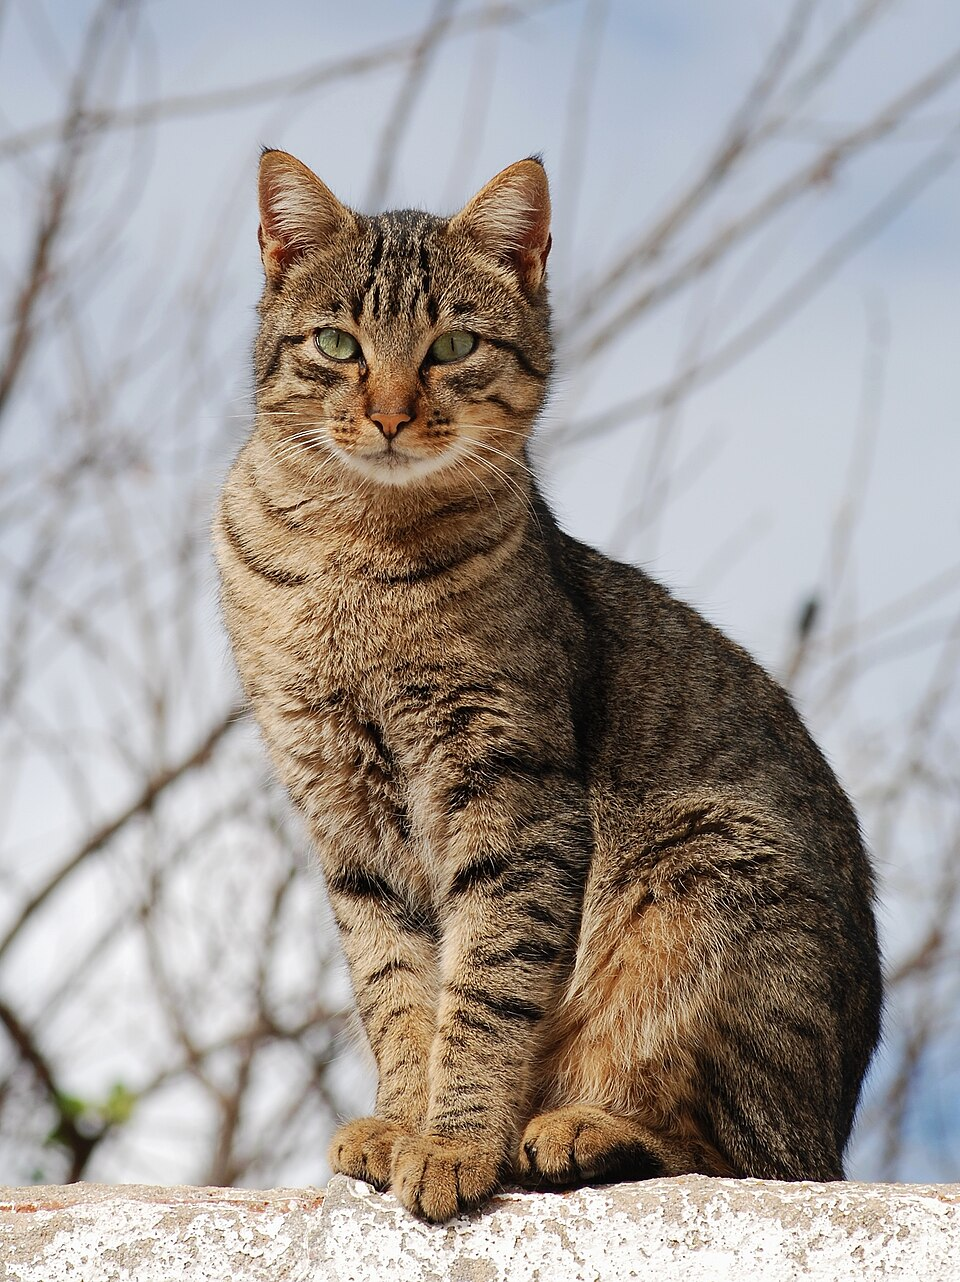

In [50]:
import base64

def analyze_image(path, model):
    with open(path, "rb") as f:
        b64 = base64.b64encode(f.read()).decode()
    prompt = """Analyze this image.

Identify:
1. Main objects
2. Environment
3. Text visible in the image
4. Possible interpretation"""
    return generate(prompt, model=model, images=[b64])

if os.path.exists(IMAGE_PATH):
    out = analyze_image(IMAGE_PATH, VISION_MODEL)
    print(out["response"], f"\nTime: {out['wall_s']:.1f}s")
    from IPython.display import Image, display
    display(Image(IMAGE_PATH, width=400))
else:
    print(f"Put an image named '{IMAGE_PATH}' next to this notebook, then run again.")

### Questions
- What is the difference between an LLM and a multimodal model?
- What extra information does the vision model receive?
- Which applications could use local vision AI? *(document analysis, OCR, industrial inspection, education, medical image preprocessing, video surveillance...)*

**Your answer:**

- **LLM vs multimodal model:** a classic LLM takes text and produces text. A multimodal model also accepts images: a vision encoder turns the image into vectors that are given to the language model together with the text tokens. `ollama show` (Part 5) shows this part for qwen3.5: a *Projector* of type `clip` with 456M parameters, which maps the image features into the 4096-dimension space of the LLM.
- **What extra information it receives:** the image itself, sent in base64 in the `images` field of the request, which the model turns into "visual tokens". With it, gemma3:4b (24.2 s) found the tabby cat, the stone wall, the bare branches, the blue sky, an outdoor scene in daylight, and correctly said there is no text in the image. The "interpretation" part is more of a guess (winter or late fall because the branches are bare, the cat looks "contemplative").
- **Applications of local vision AI:** analysis and OCR of private documents (invoices, exam copies, ID cards) without uploading them; quality inspection in a factory, where machines are often offline; education (explaining a diagram or a photo); preprocessing of medical images when data must stay in the hospital; video surveillance analysis, which raises privacy and ethical questions. In most of these cases the images are sensitive, so running locally is a real advantage.


## Part 15 — Build a Local AI Web Application
Structure:
```
local-ai-web/
├── app.py
├── templates/index.html
└── static/
```

In [51]:
!pip install -q flask requests
os.makedirs("local-ai-web/templates", exist_ok=True)
os.makedirs("local-ai-web/static", exist_ok=True)

In [52]:
%%writefile local-ai-web/app.py
import os
from flask import Flask, render_template, request
import requests

app = Flask(__name__)

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL = "qwen3.5:9b"


@app.route("/", methods=["GET", "POST"])
def index():
    answer = ""

    if request.method == "POST":
        question = request.form["question"]
        data = {"model": MODEL, "prompt": question, "stream": False}
        response = requests.post(OLLAMA_URL, json=data)
        answer = response.json()["response"]

    return render_template("index.html", answer=answer)


if __name__ == "__main__":
    app.run(host=os.environ.get("HOST", "127.0.0.1"), port=5000, debug=True, use_reloader=False)

Writing local-ai-web/app.py


In [53]:
%%writefile local-ai-web/templates/index.html
<!DOCTYPE html>
<html>
<head>
    <title>Local AI Assistant</title>
    <style>body { background: #fff; color: #222; }</style>
</head>
<body>

<h1>Local AI Assistant</h1>

<form method="POST">
    <textarea name="question" rows="8" cols="70" placeholder="Ask your local AI..."></textarea>
    <br><br>
    <button type="submit">Ask</button>
</form>

{% if answer %}
<h2>Response</h2>
<pre>{{ answer }}</pre>
{% endif %}

</body>
</html>

Writing local-ai-web/templates/index.html


On your own computer, run it **from a terminal**:
```bash
cd local-ai-web
python app.py
```
then open <http://127.0.0.1:5000>.

On Colab there is no terminal, so we start it in the background from the notebook and Colab shows the page under the cell. The Colab proxy reaches the app through the network interface of the VM, so on Colab the app listens on `0.0.0.0` (`HOST` variable); on your own computer keep the default `127.0.0.1`.


In [54]:
import subprocess, sys, time

env = {**os.environ, "HOST": "0.0.0.0" if IN_COLAB else "127.0.0.1"}
web = subprocess.Popen([sys.executable, "app.py"], cwd="local-ai-web", env=env,
                       stdout=open("web.log", "w"), stderr=subprocess.STDOUT)
for _ in range(30):                     # wait until Flask answers
    try:
        requests.get("http://127.0.0.1:5000", timeout=1); break
    except requests.exceptions.ConnectionError:
        time.sleep(1)

# quick test: send the form like the browser would
page = requests.post("http://127.0.0.1:5000", data={"question": "What is Ollama? Answer in two sentences."}, timeout=600).text
print(page[page.find("<h2>"):][:800])

if IN_COLAB:
    from google.colab.output import eval_js
    from google.colab import output
    print("Open the app:", eval_js("google.colab.kernel.proxyPort(5000)"))
    output.serve_kernel_port_as_iframe(5000, height=500)

<h2>Response</h2>
<pre>Ollama is an open-source tool designed to simplify running large language models locally on your own computer without relying on cloud services. It allows users to easily pull, manage, and interact with various AI models through a straightforward command-line interface.</pre>


</body>
</html>
Open the app: https://5000-gpu-t4-s-kkb-euw4c1-2wdxw6zq9yj06-c.europe-west4-1.prod.colab.dev


In [55]:
web.terminate(); web.wait(timeout=10)
print("Web app stopped.")

Web app stopped.


## Part 16 — Performance Benchmark
We measure: response time, model size, number of generated tokens, tokens per second, RAM and GPU memory.

Ollama returns its own counters with each answer: `eval_count` (generated tokens), `eval_duration` (ns), `prompt_eval_count`, `load_duration`.


In [56]:
!pip install -q psutil

In [57]:
%%writefile benchmark.py
"""Benchmark local Ollama models on the same prompt."""
import time, requests, psutil, pandas as pd

OLLAMA = "http://localhost:11434"
PROMPT = "Write a 500-word explanation of reinforcement learning."


def unload(model):
    requests.post(f"{OLLAMA}/api/generate", json={"model": model, "keep_alive": 0})
    time.sleep(2)


def loaded_info(model):
    for m in requests.get(f"{OLLAMA}/api/ps").json()["models"]:
        if m["name"].startswith(model.split(":")[0]):
            return m["size"] / 1e9, m.get("size_vram", 0) / 1e9
    return float("nan"), float("nan")


def bench(model, prompt=PROMPT, runs=1):
    rows = []
    for _ in range(runs):
        unload(model)                       # cold start, so the load time is visible
        t0 = time.perf_counter()
        r = requests.post(f"{OLLAMA}/api/generate",
                          json={"model": model, "prompt": prompt, "stream": False,
                                "think": False}, timeout=900).json()
        wall = time.perf_counter() - t0
        total_gb, vram_gb = loaded_info(model)
        rows.append({
            "Model": model,
            "Disk size (GB)": next((m["size"] / 1e9 for m in requests.get(f"{OLLAMA}/api/tags").json()["models"]
                                    if m["name"].startswith(model.split(":")[0])), float("nan")),
            "Loaded size (GB)": total_gb,
            "VRAM (GB)": vram_gb,
            "Load time (s)": r.get("load_duration", 0) / 1e9,
            "Response time (s)": wall,
            "Tokens": r.get("eval_count"),
            "Tokens/s": r["eval_count"] / (r["eval_duration"] / 1e9),
            "System RAM used (%)": psutil.virtual_memory().percent,
        })
    return pd.DataFrame(rows)


if __name__ == "__main__":
    import sys
    print(pd.concat([bench(m) for m in sys.argv[1:]]).round(2).to_string(index=False))

Writing benchmark.py


In [58]:
import benchmark; importlib.reload(benchmark)

bench_df = pd.concat([benchmark.bench(m) for m in (MODEL, MODEL2)], ignore_index=True)
bench_df["Quality /5"] = [5, 4]   # bench() keeps only the counters, scores from Parts 6, 10 and 14
bench_df.round(2)

,Model,Disk size (GB),Loaded size (GB),VRAM (GB),Load time (s),Response time (s),Tokens,Tokens/s,System RAM used (%),Quality /5
0,qwen3.5:9b,6.55,5.61,5.61,35.75,63.38,713,26.20,15.3,5
1,gemma3:4b,3.35,2.88,2.88,13.00,29.88,856,51.55,22.5,4


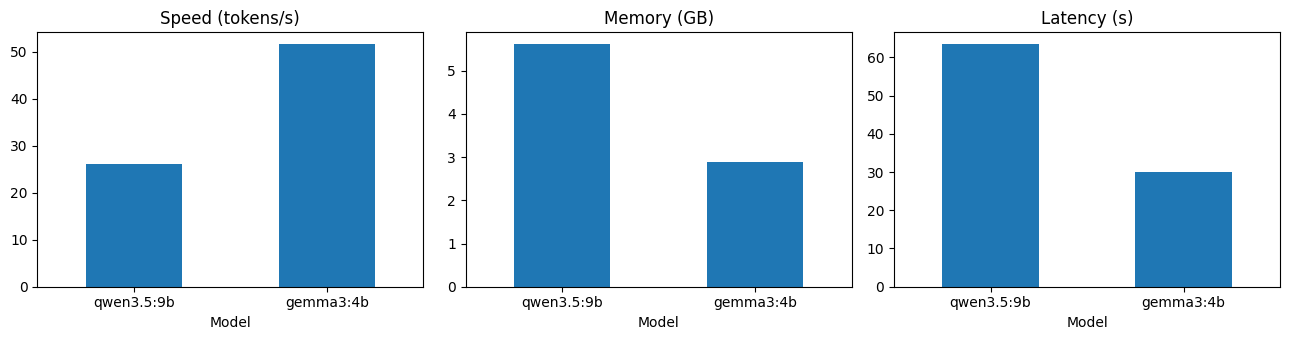

In [59]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bench_df.plot.bar(x="Model", y="Tokens/s", ax=ax[0], legend=False, title="Speed (tokens/s)", rot=0)
bench_df.plot.bar(x="Model", y="Loaded size (GB)", ax=ax[1], legend=False, title="Memory (GB)", rot=0)
bench_df.plot.bar(x="Model", y="Response time (s)", ax=ax[2], legend=False, title="Latency (s)", rot=0)
plt.tight_layout(); plt.show()

### Discussion — the model size trade-off
```
Model size ──► Quality
           ──► Memory
           ──► Latency
           ──► Hardware requirements
```
The choice of a local model should be based on **measurements on the target machine**, not only on public leaderboards.

**Your discussion:**

Measured on the Colab T4 (cold start, same 500-word prompt, thinking off):

| Model | Disk (GB) | In VRAM (GB) | Load (s) | Total time (s) | Tokens | Tokens/s |
|---|---|---|---|---|---|---|
| qwen3.5:9b | 6.55 | 5.61 | 35.8 | 63.4 | 713 | 26.2 |
| gemma3:4b | 3.35 | 2.88 | 13.0 | 29.9 | 856 | 51.6 |

- **Speed:** gemma3:4b generates about 2 times more tokens per second, and it is the model that is half the size. That is not a coincidence: to generate one token the GPU has to read all the weights from its memory, so speed is limited by memory bandwidth. 26.2 tok/s × 5.61 GB ≈ 147 GB/s and 51.6 tok/s × 2.88 GB ≈ 148 GB/s: both models read the weights at the same rate, about half of the 320 GB/s of a T4.
- **Memory:** 5.6 GB vs 2.9 GB of VRAM. Both fit in the 15 GB of the T4 at the same time, but on an 8 GB laptop the 9B model would leave little room.
- **Latency:** the total time includes loading the model (35.8 s for qwen3.5). Without the loading, the generation itself takes about 27 s for qwen3.5 and 17 s for gemma3. In normal use the model stays loaded, so only the first request pays this cost.
- **Quality:** `bench()` only keeps the counters, not the text, so the quality score comes from the other parts (Part 6 code, Part 10, Part 14): 5 for qwen3.5, 4 for gemma3.
- **RAM:** the "System RAM used" column is for the whole machine, measured after each run, so it does not isolate one model. The VRAM column is the reliable one.

Conclusion: the bigger model gives better answers but costs 2× memory and 2× time per token. For a T4, qwen3.5:9b is a good choice; for a small machine, gemma3:4b gives most of the quality at half the cost.


## Part 17 — Final Mini Project: **FSTT Local AI Assistant**

**Functional requirements:** runs entirely locally · uses Ollama + a local LLM · web interface · answers questions about a given course · uses local documents as knowledge · keeps the conversation history · structured responses for some questions · shows the answer · records the response time.

```
Browser → Flask/Python ─┬─ Conversation history ─┐
                        └─ Documents → Retriever ┴─► Ollama → Local LLM
```

We reuse `rag.py` and create the final folder:
```
LocalAI_Lab/
├── source/ (app.py, chatbot.py, rag.py, benchmark.py, templates/)
├── documents/
├── screenshots/
├── report.pdf
└── README.md
```


In [60]:
import shutil
base = "LocalAI_Lab"
for d in ("source/templates", "documents", "screenshots"):
    os.makedirs(f"{base}/{d}", exist_ok=True)

# copy shared modules and documents into the deliverable layout
shutil.copy("rag.py", f"{base}/source/rag.py")
shutil.copy("benchmark.py", f"{base}/source/benchmark.py")
for fn in os.listdir("documents"):
    shutil.copy(f"documents/{fn}", f"{base}/documents/{fn}")
print(sorted(os.listdir(base)))

['documents', 'screenshots', 'source']


In [61]:
%%writefile LocalAI_Lab/source/chatbot.py
"""Console chatbot with conversation memory (uses /api/chat)."""
import requests

OLLAMA = "http://localhost:11434"
MODEL = "qwen3.5:9b"


def main():
    messages = [{"role": "system", "content": "You are a helpful, concise assistant."}]
    print("Local AI Assistant — type 'exit' to stop.")
    while True:
        q = input("\nYou: ")
        if q.lower() == "exit":
            break
        messages.append({"role": "user", "content": q})
        r = requests.post(f"{OLLAMA}/api/chat",
                          json={"model": MODEL, "messages": messages, "stream": False})
        r.raise_for_status()
        reply = r.json()["message"]
        messages.append({"role": "assistant", "content": reply["content"]})
        print("\nAI:", reply["content"])


if __name__ == "__main__":
    main()

Writing LocalAI_Lab/source/chatbot.py


In [62]:
%%writefile LocalAI_Lab/source/app.py
"""FSTT Local AI Assistant — Flask + Ollama + local RAG + conversation history."""
import csv, json, os, time
from datetime import datetime
import requests
from flask import Flask, jsonify, render_template, request

import rag

OLLAMA = os.environ.get("OLLAMA_URL", "http://localhost:11434")
MODEL = os.environ.get("MODEL", "qwen3.5:9b")
DOC_DIR = os.path.join(os.path.dirname(__file__), "..", "documents")
MAX_TURNS = 6                      # remembered user/assistant pairs
LOG_FILE = os.path.join(os.path.dirname(__file__), "response_times.csv")

app = Flask(__name__)
retriever = rag.Retriever(rag.load_documents(DOC_DIR))
history = []                       # [{"role": ..., "content": ...}]  (single-user demo)

SYSTEM = ("You are the FSTT Local AI Assistant. Answer questions about the course using only the "
          "provided CONTEXT. If the answer is not in the context, say: \"Information not available.\" "
          "Be concise.")

# Structured response schema used for "Analyze ..." / "Quiz ..." style questions
STRUCT_SCHEMA = {
    "type": "object",
    "properties": {
        "topic": {"type": "string"},
        "summary": {"type": "string"},
        "key_points": {"type": "array", "items": {"type": "string"}},
        "difficulty": {"type": "string", "enum": ["easy", "medium", "hard"]},
    },
    "required": ["topic", "summary", "key_points", "difficulty"],
}


def call_ollama(messages, structured=False):
    payload = {"model": MODEL, "messages": messages, "stream": False, "think": False}
    if structured:
        payload["format"] = STRUCT_SCHEMA
    r = requests.post(f"{OLLAMA}/api/chat", json=payload, timeout=600)
    r.raise_for_status()
    return r.json()


def record(question, structured, seconds, tokens, tps):
    """Append one line per answer to response_times.csv."""
    new_file = not os.path.exists(LOG_FILE)
    with open(LOG_FILE, "a", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        if new_file:
            w.writerow(["time", "question", "structured", "seconds", "tokens", "tokens_per_s"])
        w.writerow([datetime.now().isoformat(timespec="seconds"), question, structured,
                    round(seconds, 2), tokens, round(tps, 1) if tps else ""])


@app.route("/")
def index():
    return render_template("index.html", model=MODEL, docs=list(retriever.docs))


@app.route("/ask", methods=["POST"])
def ask():
    body = request.get_json(force=True)
    question = (body.get("question") or "").strip()
    structured = bool(body.get("structured"))
    if not question:
        return jsonify(error="Empty question"), 400

    hits, context = retriever.context(question, k=2)
    user_msg = f"CONTEXT:\n{context or '(none)'}\n\nQUESTION: {question}"
    messages = [{"role": "system", "content": SYSTEM}] + history[-2 * MAX_TURNS:] \
               + [{"role": "user", "content": user_msg}]

    t0 = time.perf_counter()
    try:
        out = call_ollama(messages, structured)
    except requests.RequestException as e:
        return jsonify(error=f"Ollama error: {e}"), 502
    elapsed = time.perf_counter() - t0

    answer = out["message"]["content"]
    # store the plain question (not the long context) to keep history small
    history.append({"role": "user", "content": question})
    history.append({"role": "assistant", "content": answer})

    parsed = None
    if structured:
        try:
            parsed = json.loads(answer)
        except json.JSONDecodeError:
            pass

    tokens = out.get("eval_count")
    tps = tokens / (out["eval_duration"] / 1e9) if tokens and out.get("eval_duration") else None
    record(question, structured, elapsed, tokens, tps)
    return jsonify(answer=answer, structured=parsed,
                   sources=[{"doc": n, "score": round(s, 2)} for n, s in hits],
                   seconds=round(elapsed, 2), tokens=tokens,
                   tokens_per_s=round(tps, 1) if tps else None)


@app.route("/reset", methods=["POST"])
def reset():
    history.clear()
    return jsonify(ok=True)


if __name__ == "__main__":
    # localhost by default (see Q15 on security); HOST=0.0.0.0 only for the Colab proxy
    app.run(host=os.environ.get("HOST", "127.0.0.1"), port=int(os.environ.get("PORT", 5001)), debug=False)

Writing LocalAI_Lab/source/app.py


In [63]:
%%writefile LocalAI_Lab/source/templates/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<title>FSTT Local AI Assistant</title>
<style>
  body { font-family: system-ui, sans-serif; max-width: 820px; margin: 2rem auto; padding: 0 1rem; color:#222; background:#fff; }
  h1 { margin-bottom: .2rem; } .sub { color:#666; font-size:.9rem; margin-bottom:1rem; }
  #chat { border:1px solid #ddd; border-radius:8px; padding:1rem; height:420px; overflow-y:auto; background:#fafafa; }
  .msg { margin:.6rem 0; padding:.6rem .8rem; border-radius:8px; white-space:pre-wrap; }
  .user { background:#e3f0ff; } .ai { background:#fff; border:1px solid #e5e5e5; }
  .meta { font-size:.75rem; color:#777; margin-top:.3rem; }
  form { display:flex; gap:.5rem; margin-top:1rem; } input[type=text] { flex:1; padding:.6rem; }
  button { padding:.6rem 1rem; cursor:pointer; } label { font-size:.85rem; }
</style>
</head>
<body>
<h1>FSTT Local AI Assistant</h1>
<div class="sub">Model: <b>{{ model }}</b> · Documents: {{ docs|join(", ") }} · Runs 100% locally</div>
<div id="chat"></div>
<form id="f">
  <input type="text" id="q" placeholder="Ask a question about the course..." autocomplete="off" autofocus>
  <button type="submit">Ask</button>
  <button type="button" id="reset">Reset</button>
</form>
<label><input type="checkbox" id="struct"> Structured response (JSON)</label>

<script>
const chat = document.getElementById("chat");
function add(cls, text, meta) {
  const d = document.createElement("div"); d.className = "msg " + cls; d.textContent = text;
  if (meta) { const m = document.createElement("div"); m.className = "meta"; m.textContent = meta; d.appendChild(m); }
  chat.appendChild(d); chat.scrollTop = chat.scrollHeight; return d;
}
document.getElementById("f").onsubmit = async (e) => {
  e.preventDefault();
  const q = document.getElementById("q"); const question = q.value.trim(); if (!question) return;
  q.value = ""; add("user", question);
  const wait = add("ai", "thinking...");
  try {
    const r = await fetch("/ask", {method:"POST", headers:{"Content-Type":"application/json"},
      body: JSON.stringify({question, structured: document.getElementById("struct").checked})});
    const j = await r.json(); wait.remove();
    if (j.error) { add("ai", "Error: " + j.error); return; }
    const text = j.structured ? JSON.stringify(j.structured, null, 2) : j.answer;
    const src = j.sources.map(s => s.doc).join(", ") || "none";
    add("ai", text, `${j.seconds}s · ${j.tokens ?? "?"} tokens · ${j.tokens_per_s ?? "?"} tok/s · sources: ${src}`);
  } catch (err) { wait.remove(); add("ai", "Error: " + err); }
};
document.getElementById("reset").onclick = async () => { await fetch("/reset", {method:"POST"}); chat.innerHTML = ""; };
</script>
</body>
</html>

Writing LocalAI_Lab/source/templates/index.html


In [64]:
%%writefile LocalAI_Lab/README.md
# FSTT Local AI Assistant

A fully local assistant: Flask web interface → Ollama → local LLM, with a keyword (TF-IDF) retriever over `documents/`,
conversation history, structured (JSON) answers and the response time.
Each answer is also recorded in `source/response_times.csv` (time, question, seconds, tokens, tokens/s).

## Setup
```bash
ollama pull qwen3.5:9b
pip install flask requests psutil pandas
```

## Run
```bash
cd source
python app.py            # http://127.0.0.1:5001
python chatbot.py        # console chatbot
python benchmark.py qwen3.5:9b gemma3:4b
```
Environment variables: `MODEL`, `OLLAMA_URL`, `PORT`, `HOST` (default `127.0.0.1`).

## Documents
`ai.txt`, `machine_learning.txt`, `reinforcement_learning.txt` and `deep_learning.txt` are the course files of the mini-RAG
(the deliverable list calls the last ones `ml.txt` and `rl.txt`; the lab code creates them with the long names).
`course.txt` is the short course file of Part 12.

Writing LocalAI_Lab/README.md


**Test the final app from the notebook:** start it in the background, send a few questions, then stop it.

In [65]:
import subprocess, sys, time

env = {**os.environ, "MODEL": MODEL, "PORT": "5001", "HOST": "0.0.0.0" if IN_COLAB else "127.0.0.1"}
server = subprocess.Popen([sys.executable, "app.py"], cwd="LocalAI_Lab/source", env=env,
                          stdout=open("app.log", "w"), stderr=subprocess.STDOUT)
for _ in range(30):                     # wait until Flask answers
    try:
        requests.get("http://127.0.0.1:5001", timeout=1); break
    except requests.exceptions.ConnectionError:
        time.sleep(1)

def app_ask(q, structured=False):
    r = requests.post("http://127.0.0.1:5001/ask", json={"question": q, "structured": structured}, timeout=600)
    return r.json()

for q, s in [("What is reinforcement learning?", False),
             ("And how is it different from supervised learning?", False),   # tests the history
             ("Summarize deep learning", True),                              # structured
             ("What is quantum computing?", False)]:                         # not in the documents
    j = app_ask(q, s)
    print(f"Q: {q}\nA: {j.get('structured') or j.get('answer') or j}\n"
          f"   sources={j.get('sources')} · {j.get('seconds')}s · {j.get('tokens_per_s')} tok/s\n")

# the server keeps running so you can open it in the browser, it is stopped two cells below
if IN_COLAB:
    from google.colab.output import eval_js
    from google.colab import output
    print("Open the app:", eval_js("google.colab.kernel.proxyPort(5001)"))
    output.serve_kernel_port_as_iframe(5001, height=700)

Q: What is reinforcement learning?
A: Reinforcement learning is a branch of artificial intelligence where an agent learns through interaction with an environment using rewards and penalties. An agent observes a state, chooses an action, and receives a reward, with the goal of learning a policy that maximises cumulative reward. Common algorithms include Q-learning and policy gradients.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'reinforcement_learning.txt', 'score': 1.02}] · 3.07s · 24.7 tok/s

Q: And how is it different from supervised learning?
A: Supervised learning uses labelled data to learn a mapping from inputs to outputs, whereas reinforcement learning learns through interaction with an environment using rewards and penalties.
   sources=[{'doc': 'course.txt', 'score': 1.08}, {'doc': 'machine_learning.txt', 'score': 1.06}] · 1.82s · 24.3 tok/s

Q: Summarize deep learning
A: {'difficulty': 'hard', 'key_points': ['Uses artificial neural networks with many layers', '

In [66]:
server.terminate(); server.wait(timeout=10)
print("Server stopped.")

Server stopped.


Open the app in your browser while the server is running and take your screenshots: `01_installation.png`, `02_model.png`, `03_chatbot.png`, `04_python.png`, `05_rag.png`, `06_webapp.png`.

## Part 18 — Questions for the Report
Answers based on the measurements of this notebook (Colab, T4 GPU).

**Q1.** What is Local AI?

Local AI means running the AI model on your own machine (laptop, server, or here the Colab VM) instead of sending the requests to a provider's cloud. The model weights are downloaded once, and then the prompts, the documents and the answers stay on the machine. In this lab: Ollama running `qwen3.5:9b` and `gemma3:4b` on a T4 GPU, used from Python through `localhost:11434`.

**Q2.** Difference between a Cloud LLM and a Local LLM?

| | Cloud LLM | Local LLM |
|---|---|---|
| Where it runs | Provider's servers | My machine |
| Data | Sent over the Internet to a third party | Stays on the machine |
| Cost | Pay per token / subscription | Hardware + electricity, no cost per token |
| Internet | Required | Only to download the model |
| Model size | Very large (hundreds of billions of parameters) | Limited by my memory (here 4B and 9B) |
| Quality | Usually better | Lower, depends on the model |
| Speed | Fast, big GPUs | Depends on my hardware (26 to 52 tok/s on a T4) |
| Control | Provider can change or remove the model | I choose and keep the exact version |

**Q3.** What role does Ollama play?

Ollama is the program between my application and the model. It:
- downloads models from its library and stores them (`ollama pull`, `ollama list`);
- loads them into the GPU or the RAM, decides how much goes on the GPU, and unloads them after some idle time (`ollama ps`, `keep_alive`);
- runs the inference with its engine (llama.cpp runner here) and applies the chat template of each model;
- exposes everything as a REST API on port 11434 (`/api/generate`, `/api/chat`, `/api/embed`, `/api/tags`, `/api/ps`, `/api/show`), with options like structured outputs and thinking on/off.

It is a bit like Docker for models: one command to get a model and one standard interface to use any of them.

**Q4.** What is model quantization?

Quantization means storing the weights of the model with fewer bits. A model is normally trained in 16 or 32-bit floats. With `Q4_K_M` (our qwen3.5:9b), most weights use about 4 bits: they are grouped in blocks, and each block keeps a scale factor to rebuild approximate values. The "M" (medium) variant keeps some sensitive tensors at higher precision.

Example: 9 billion parameters in 16 bits would take about 18 GB, more than the T4 has. Quantized, the file is 6.6 GB and it runs at 26 tokens/s. We lose a little quality but gain a lot of memory and speed.

**Q5.** Why does model size affect memory consumption?

Because all the weights have to be in memory to generate each token. Memory needed ≈ number of parameters × bytes per parameter, plus the KV cache (the memory of the context, which grows with the context length) and some buffers. That is why the 9B model takes 5.6 GB of VRAM and the 4B model 2.9 GB, both in 4-bit quantization. If the model does not fit in the GPU, Ollama puts part of it on the CPU and it becomes much slower.

**Q6.** Why can a smaller model sometimes be preferable?

- It fits on machines with little memory (gemma3:4b uses 2.9 GB, qwen3.5:9b 5.6 GB).
- It is faster: 51.6 vs 26.2 tokens/s, and 13 s vs 36 s to load in my benchmark.
- For simple tasks it is good enough: gemma3:4b wrote a correct `is_prime`, found the right objects in the image, and for RAG the answer comes from the documents anyway, so the model does not need a lot of knowledge.
- It uses less energy and leaves room for other programs or other models on the same GPU.

**Q7.** Advantages of local inference?

- **Privacy:** the data never leaves the machine (important for medical, legal or student data, and for GDPR).
- **Offline:** it works without Internet once the model is downloaded.
- **Cost:** no price per token, so you can run as many requests as you want (the benchmark, the tests...).
- **Control:** I pin an exact version (`qwen3.5:9b`), nobody can change or remove it, and there are no rate limits.
- **Customization:** system prompts, parameters, choice of model for each task.

**Q8.** Disadvantages of local inference?

- **Hardware:** you need enough RAM / VRAM; big models are impossible on a normal laptop.
- **Quality:** small models make more mistakes. In this lab: "every Git commit has one parent" (Part 4), or a student with 15.5 marked "high risk" (Part 11).
- **Speed:** on weak hardware it is slow. Even on the T4, the first answer with thinking took 150 s.
- **Work for me:** installation, updates, monitoring, security; there is no team behind it like with a cloud API.
- **Scaling:** one GPU serves a few users, not thousands.
- **Energy and disk:** the models take several GB each.

**Q9.** Explain the architecture of your Python application.

The final app (Part 17) has these layers:

1. **Browser:** `index.html` with a little JavaScript that sends the question to `/ask` with `fetch()` and shows the answer, the sources, the time and the tokens/s.
2. **Flask (`app.py`):** three routes: `/` (the page), `/ask` (one question) and `/reset` (clear the history).
3. **Retriever (`rag.py`):** a keyword TF-IDF score over the files of `documents/`; the 2 best documents become the CONTEXT.
4. **Prompt building:** a system message (answer only from the context, otherwise "Information not available."), the last 6 exchanges from `history`, and the new question with its context.
5. **Ollama:** POST to `/api/chat` with `think: false`, and a JSON Schema in `format` when the "structured" box is checked.
6. **Response:** Flask stores the question and the answer in the history (the question without the context, to keep it small) and returns JSON with the answer, sources, seconds and tokens/s.
7. **Recording:** each answer is appended to `response_times.csv` (time, question, structured or not, seconds, tokens, tokens/s).

In the test, the app answered in 0.7 to 7.5 s, understood the follow-up question "And how is it different from supervised learning?" thanks to the history, returned a valid JSON summary of deep learning, and answered "Information not available." for quantum computing. In a second test, `response_times.csv` recorded 1.84 s (45 tokens, 31.1 tok/s) for a normal answer and 5.84 s (141 tokens, 26.2 tok/s) for a structured one.

**Q10.** Explain the role of the REST API.

The REST API is the interface between my code and the model. My program only sends an HTTP request with JSON (model, prompt or messages, options) and receives JSON (the answer and counters like `eval_count`). So:
- any language or tool can use the model: Python `requests`, Flask, JavaScript, `curl`;
- the application does not depend on how the model runs: to change the model I change one string, and to use another machine I change `OLLAMA_URL`;
- the same API is used for everything: generation, chat, embeddings, list of models, loaded models.

The API is stateless: each request must contain everything the model needs, which is why we resend the history (Part 9).

**Q11.** What is RAG?

RAG (Retrieval-Augmented Generation) means: first **retrieve** the documents related to the question, then put them in the prompt, and let the model **generate** the answer from them. It lets the model answer about information it never saw in training (a course, private files), reduces hallucinations, allows showing the sources, and the knowledge can be updated just by changing the documents, without training.

In our mini-RAG the retriever is a simple keyword TF-IDF. It worked (GPUs for deep learning, refusal for the World Cup), but I saw its limits: for "What is reinforcement learning?" it picked `course.txt` instead of `reinforcement_learning.txt`, and for "What hardware accelerates network training?" two documents got exactly the same score (0.875). With embeddings (`nomic-embed-text`) the semantic search clearly put `deep_learning.txt` first (0.64), because it compares meanings and not words. Real RAG systems use embeddings, cut documents into chunks and store them in a vector database.

**Q12.** Difference between an LLM and a multimodal LLM?

An LLM only works with text (text in, text out). A multimodal LLM also takes other inputs, here images: a vision encoder (for example CLIP) turns the image into vectors and a projector maps them into the embedding space of the LLM, so the model reads the image as extra tokens next to the text. In Part 14, gemma3:4b received the photo in base64 and described the cat, the wall and the sky. qwen3.5:9b is multimodal too: `ollama show` lists the `vision` capability and a CLIP projector of 456M parameters.

**Q13.** Compare two local models experimentally.

Same T4 GPU, same prompts:

| | qwen3.5:9b | gemma3:4b |
|---|---|---|
| Parameters / quantization | 9.0B / Q4_K_M | 4B / Q4_K_M |
| Disk / VRAM | 6.55 GB / 5.61 GB | 3.35 GB / 2.88 GB |
| Load time (cold) | 35.8 s | 13.0 s |
| Speed | 26.2 tokens/s | 51.6 tokens/s |
| `is_prime` (Part 6) | correct, 40.3 s | correct, 43.3 s |
| Quality /5 | 5 | 4 |

gemma3:4b is twice as fast and uses half the memory; qwen3.5:9b writes cleaner and more complete answers and has a thinking mode. Speed × size is almost constant (≈ 147 GB/s for both), which shows that generation is limited by the memory bandwidth of the GPU.

**Q14.** Which model would you deploy on a computer with limited RAM? Explain.

gemma3:4b. Loaded, it needs 2.9 GB, against 5.6 GB for qwen3.5:9b, and on a computer with limited RAM you must also keep memory for the system, the context and the other programs. With 8 GB of RAM and no GPU, the 9B model would fill almost everything and become very slow. In my tests gemma3:4b was still correct on the code and on the image, and it is twice as fast. With even less memory (4 GB), I would take `gemma3:1b` or `qwen3.5:2b`, and accept lower quality.

**Q15.** What security risks exist when exposing a local LLM server to a network?

By default Ollama only listens on `127.0.0.1` (the install script says it: "The Ollama API is now available at 127.0.0.1:11434"), so only the same machine can use it. If you set `OLLAMA_HOST=0.0.0.0`, anyone who can reach port 11434 can use it, because **there is no authentication**:
- **Use of my compute:** anyone can send requests and use my GPU, or flood it so it is unavailable for me.
- **Model management:** the API can also pull, copy and delete models (`/api/pull`, `/api/delete`) and list what I have.
- **Data exposure:** the prompts often contain private data. In our Flask app the `history` is one global list, so a second user would get the conversation of the first one in their context.
- **Prompt injection through documents:** a file in `documents/` containing "ignore the previous instructions..." goes straight into the prompt.
- **No TLS:** traffic is plain HTTP, so it can be read on the network.
- **Flask debug mode:** the Part 15 app runs with `debug=True`. The Werkzeug debugger is an interactive Python console in the browser, protected only by a PIN; it must never be reachable from a network.

Protection: keep Ollama on `localhost`; if remote access is needed, put a reverse proxy (nginx, Caddy) in front of it with authentication and HTTPS, or use a VPN / SSH tunnel; block port 11434 with a firewall; turn off debug mode; one history per user; and treat the documents as untrusted input.

On Colab I had to start the Flask app with `HOST=0.0.0.0`, because the Colab proxy does not reach an app listening only on `127.0.0.1`. That was acceptable there because the VM has no public port: the page is only reachable through the Colab proxy, after logging in to my Google account. On a laptop or a server on a real network, I would keep `127.0.0.1`.


## Part 19 — Deliverables
Final check of the submission folder:
```
LocalAI_Lab/
├── report.pdf
├── source/        app.py · chatbot.py · rag.py · benchmark.py
├── documents/     ai.txt · ml.txt · rl.txt  (+ the other course files)
├── screenshots/   01_installation.png … 06_webapp.png
└── README.md
```

In [67]:
required = [
    "LocalAI_Lab/report.pdf",
    "LocalAI_Lab/README.md",
    "LocalAI_Lab/source/app.py", "LocalAI_Lab/source/chatbot.py",
    "LocalAI_Lab/source/rag.py", "LocalAI_Lab/source/benchmark.py",
    "LocalAI_Lab/screenshots/01_installation.png", "LocalAI_Lab/screenshots/02_model.png",
    "LocalAI_Lab/screenshots/03_chatbot.png", "LocalAI_Lab/screenshots/04_python.png",
    "LocalAI_Lab/screenshots/05_rag.png", "LocalAI_Lab/screenshots/06_webapp.png",
]
for p in required:
    print("ok     " if os.path.exists(p) else "missing", p)
print("\nDocuments:", sorted(os.listdir("LocalAI_Lab/documents")))

missing LocalAI_Lab/report.pdf
ok      LocalAI_Lab/README.md
ok      LocalAI_Lab/source/app.py
ok      LocalAI_Lab/source/chatbot.py
ok      LocalAI_Lab/source/rag.py
ok      LocalAI_Lab/source/benchmark.py
missing LocalAI_Lab/screenshots/01_installation.png
missing LocalAI_Lab/screenshots/02_model.png
missing LocalAI_Lab/screenshots/03_chatbot.png
missing LocalAI_Lab/screenshots/04_python.png
missing LocalAI_Lab/screenshots/05_rag.png
missing LocalAI_Lab/screenshots/06_webapp.png

Documents: ['ai.txt', 'course.txt', 'deep_learning.txt', 'machine_learning.txt', 'reinforcement_learning.txt']
